[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abhishek12198/entriMiniProject/blob/main/ML_Assignment_5_Clustering.ipynb)

# Iris clustering

Open this notebook in Google Colab with the button above, then use **Runtime → Run all**. Each code cell runs in order, and the plots and printed numbers appear under that cell.

Two clustering methods are fit on the Iris dataset from scikit-learn. Each row is one flower. The four features are sepal length, sepal width, petal length, and petal width, in centimetres. The species name is a label, so it is removed before either algorithm runs. Clustering has to form groups from the measurements alone.

K-Means and hierarchical clustering both use Euclidean distance, so both see the same scaled table. The stack is scikit-learn, pandas, NumPy, Matplotlib, and SciPy.


## 1. Setup

Imports stay inside that stack so the notebook runs in a clean Colab session.


In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage


## 2. Load the dataset and drop the species column

`load_iris` returns 150 flowers and 4 numeric measurements. The fifth field is the species name: setosa, versicolor, or virginica, with 50 flowers each.

That name is the group a clustering algorithm is supposed to discover, not an input. The cell below builds a table that includes species, prints the counts, then drops the column. Every later step uses only the four measurements.


In [2]:
dataset = load_iris()
iris = pd.DataFrame(dataset.data, columns=dataset.feature_names)
iris["species"] = dataset.target_names[dataset.target]

print(f"Rows before dropping species: {iris.shape[0]}")
print(f"Columns before dropping species: {list(iris.columns)}")
print()
print(iris["species"].value_counts().to_string())
print()

X = iris.drop(columns=["species"])
print(f"Feature matrix used for clustering: {X.shape[0]} rows, {X.shape[1]} columns")
print(f"Columns kept: {list(X.columns)}")
X.head(3)


Rows before dropping species: 150
Columns before dropping species: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species']

species
setosa        50
versicolor    50
virginica     50

Feature matrix used for clustering: 150 rows, 4 columns
Columns kept: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2


## 3. Missing values and scaling

The published Iris table has no blank cells. The count is still checked, because a distance cannot be computed from a missing measurement, and there is nothing to impute if the count is zero.

The four columns share a unit (centimetres) but not a range. Petal length runs from about 1 cm to about 7 cm. Sepal width runs from about 2 cm to about 4.4 cm. K-Means and Ward hierarchical clustering both group flowers by Euclidean distance, so a column with a wider raw range pulls the distance more than a narrower one. Standard scaling puts each column in units of its own standard deviation. The scaler is fit on the full table: this is clustering of the whole sample, not a train/test prediction task, so there is no held-out block whose mean must be kept out.


In [3]:
missing = int(X.isna().sum().sum())
print(f"Missing feature values: {missing} of {X.shape[0] * X.shape[1]}")

spread = X.agg(["min", "max", "std"]).T
spread["range"] = spread["max"] - spread["min"]
print()
print(spread.round(3).to_string())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print()
print(
    "After scaling: "
    f"mean of means = {X_scaled.mean():.6f}, "
    f"mean of stds = {X_scaled.std(axis=0).mean():.4f}"
)


Missing feature values: 0 of 600

                   min  max    std  range
sepal length (cm)  4.3  7.9  0.828    3.6
sepal width (cm)   2.0  4.4  0.436    2.4
petal length (cm)  1.0  6.9  1.765    5.9
petal width (cm)   0.1  2.5  0.762    2.4

After scaling: mean of means = -0.000000, mean of stds = 1.0000


## 4. K-Means

K-Means looks for a fixed number of groups, k.

1. Place k centres in the feature space.
2. Assign every flower to the nearest centre.
3. Move each centre to the mean of the flowers assigned to it.
4. Repeat the assignment and the update until the centres stop moving.

The result is a partition of the 150 flowers. Points near the same centre share a cluster. The algorithm minimises the sum of squared distances from each flower to its centre, which is why the clusters it prefers are compact and roughly round in the scaled space.

K-Means fits this table. There are only four numeric columns and 150 rows, so distance to a centre is cheap and stable. The measurements of these flowers form a few compact clouds rather than long intertwined curves, which is the shape a centre-and-radius model can represent. The number of groups is chosen from the data below, without putting the species name back in.


## 5. How many clusters

Inertia is the sum of squared distances to the centres. It always falls as k grows, because more centres can only sit closer to the points. The useful k is where the curve bends: extra clusters after the bend buy little tightness.

Silhouette compares, for each flower, the distance to its own cluster with the distance to the nearest other cluster. It is reported for k from 2 upward. A higher score means the groups are more separated. Both checks use the scaled measurements only.


 k  inertia  silhouette
 1 600.0000         NaN
 2 222.3617      0.5818
 3 139.8205      0.4599
 4 114.0925      0.3869
 5  90.9275      0.3459
 6  81.5444      0.3171
 7  72.6311      0.3202
 8  62.5406      0.3387


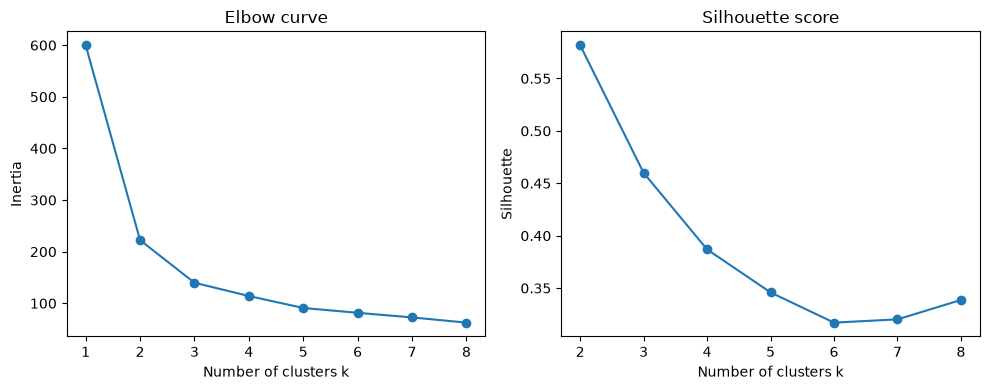

In [4]:
inertias = []
silhouettes = []
k_values = range(1, 9)
for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels) if k > 1 else np.nan)

choice = pd.DataFrame({
    "k": list(k_values),
    "inertia": inertias,
    "silhouette": silhouettes,
})
print(choice.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(choice["k"], choice["inertia"], marker="o")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow curve")
axes[0].set_xticks(list(k_values))

axes[1].plot(choice.loc[choice["k"] > 1, "k"], choice.loc[choice["k"] > 1, "silhouette"], marker="o")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette")
axes[1].set_title("Silhouette score")
axes[1].set_xticks(list(range(2, 9)))
fig.tight_layout()
plt.show()


## 6. Fit K-Means with k = 3

Inertia falls from 600 at one cluster to 222 at two, then to 140 at three. The next step, three to four, only reaches 114. The steep part of the curve ends at three, so three is the elbow.

The silhouette is highest at two clusters (0.58), then 0.46 at three. Two wins that score because one cloud of flowers sits far from the other flowers, and the remaining flowers overlap. A third centre still tightens the fit by a large amount, and a fourth centre does not. K-Means is therefore fit with k = 3. `n_init=10` restarts the centres ten times and keeps the tightest result. `random_state=42` makes that choice repeatable.


In [5]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

centres_cm = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=X.columns,
)
centres_cm.insert(0, "cluster", centres_cm.index)
sizes = pd.Series(kmeans_labels).value_counts().sort_index()
print("Flowers per K-Means cluster:")
print(sizes.to_string())
print()
print("Cluster centres, converted back to centimetres:")
print(centres_cm.round(2).to_string(index=False))
print()
print(f"Silhouette at k=3: {silhouette_score(X_scaled, kmeans_labels):.4f}")


Flowers per K-Means cluster:
0    53
1    50
2    47

Cluster centres, converted back to centimetres:
 cluster  sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
       0               5.80              2.67               4.37              1.41
       1               5.01              3.43               1.46              0.25
       2               6.78              3.10               5.51              1.97

Silhouette at k=3: 0.4599


## 7. K-Means clusters on a plot

The algorithm was fit on all four scaled columns. A plot can only show two axes at a time, so there are two views of the same labels.

The first view uses petal length and petal width in the original centimetres. Those two columns carry most of the separation, which is why the groups are easy to see there. The second view is a principal-component plot of the four scaled columns: two directions chosen only to spread the points out for display. The clustering itself was not run on those two components. Black rings mark the K-Means centres in that same view.


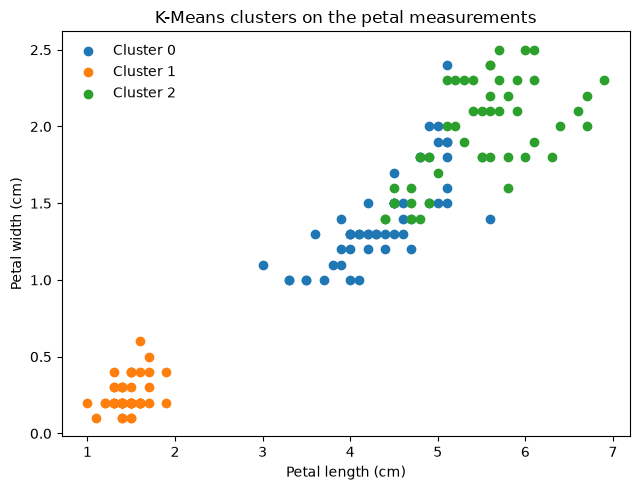

Share of scaled variance on the two plot axes: 0.958


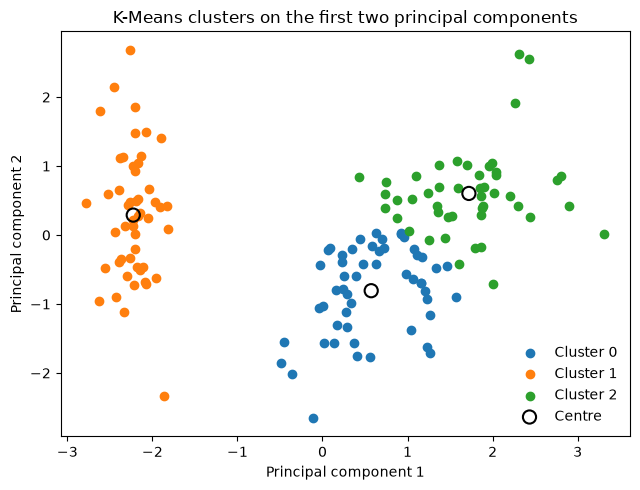

In [6]:
def scatter_clusters(x, y, labels, xlabel, ylabel, title, centres=None):
    fig, ax = plt.subplots(figsize=(6.5, 5))
    for cluster in np.unique(labels):
        mask = labels == cluster
        ax.scatter(x[mask], y[mask], s=36, label=f"Cluster {cluster}")
    if centres is not None:
        ax.scatter(
            centres[:, 0],
            centres[:, 1],
            marker="o",
            s=90,
            facecolors="none",
            edgecolors="black",
            linewidths=1.5,
            label="Centre",
        )
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()


petal_length = X["petal length (cm)"].to_numpy()
petal_width = X["petal width (cm)"].to_numpy()
scatter_clusters(
    petal_length,
    petal_width,
    kmeans_labels,
    "Petal length (cm)",
    "Petal width (cm)",
    "K-Means clusters on the petal measurements",
)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
centres_pca = pca.transform(kmeans.cluster_centers_)
print(
    "Share of scaled variance on the two plot axes: "
    f"{pca.explained_variance_ratio_.sum():.3f}"
)
scatter_clusters(
    X_pca[:, 0],
    X_pca[:, 1],
    kmeans_labels,
    "Principal component 1",
    "Principal component 2",
    "K-Means clusters on the first two principal components",
    centres=centres_pca,
)


## 8. Hierarchical clustering

Hierarchical clustering does not start from a chosen k. Agglomerative clustering starts with each flower as its own cluster, then merges the two closest clusters, and repeats until every flower sits in one cluster. The record of those merges is a tree.

The closeness of two clusters depends on the linkage. Ward linkage merges the pair whose union increases the total within-cluster variance by the smallest amount. That is the same squared-distance idea K-Means uses, applied as a sequence of merges instead of a move of k centres.

This table is a good fit for that procedure. One hundred and fifty rows is small enough to build the full tree. The tree shows the merge order, so the cut into three groups can be checked against the picture rather than assumed up front. Ward linkage looks for the same compact groups that the scaled Iris measurements can support. The dendrogram below is drawn from the scaled features. Leaf names are hidden because 150 species labels would be unreadable, and those labels were dropped anyway.


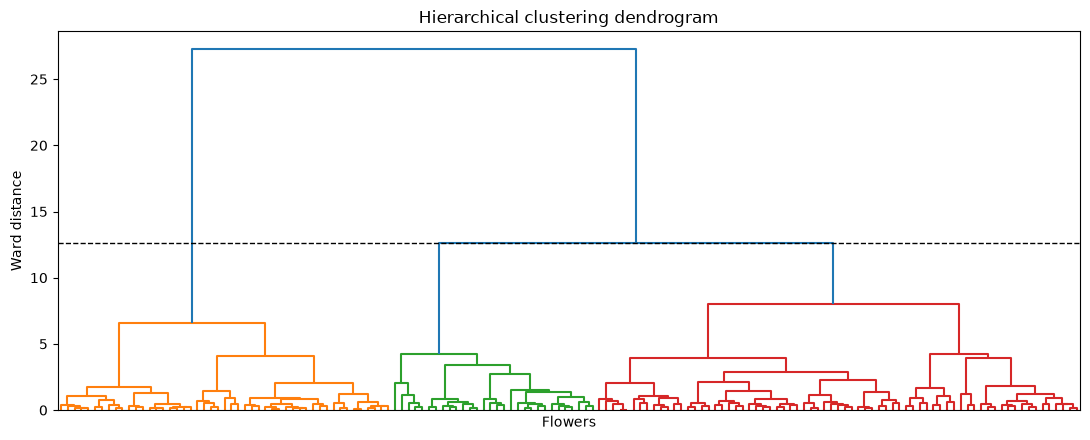

Height of the cut that leaves three clusters: 12.637


In [7]:
merge_tree = linkage(X_scaled, method="ward")
# The merge that joins three clusters into two sits one step before the final merge.
cut_height = merge_tree[-2, 2]

fig, ax = plt.subplots(figsize=(11, 4.5))
dendrogram(merge_tree, no_labels=True, color_threshold=cut_height, ax=ax)
ax.axhline(cut_height, color="black", linestyle="--", linewidth=1)
ax.set_ylabel("Ward distance")
ax.set_xlabel("Flowers")
ax.set_title("Hierarchical clustering dendrogram")
fig.tight_layout()
plt.show()
print(f"Height of the cut that leaves three clusters: {cut_height:.3f}")


## 9. Cut the tree into three clusters

The dashed line on the dendrogram is the height where three branches remain. Agglomerative clustering with Ward linkage and `n_clusters=3` makes that cut and returns one label per flower. The same two views used for K-Means show the result: petal length against petal width, and the first two principal components of the scaled table. The principal components are the same display axes as before. They are not a new clustering.


Flowers per hierarchical cluster:
0    71
1    49
2    30

Silhouette at 3 clusters: 0.4467


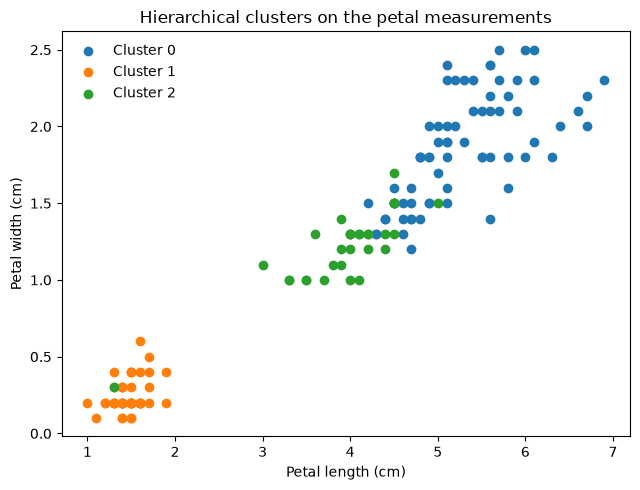

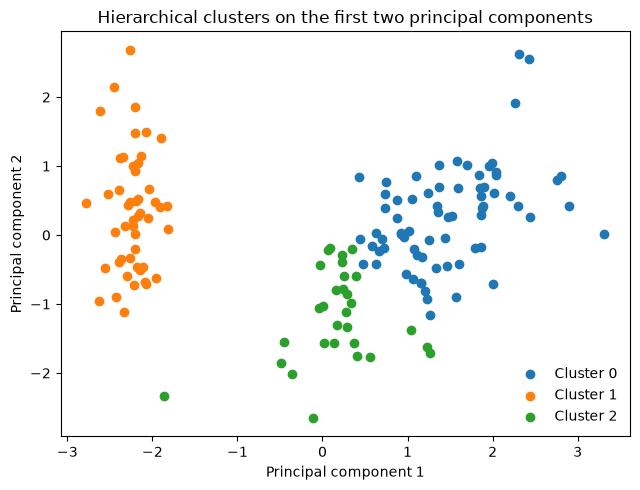

In [8]:
hierarchical = AgglomerativeClustering(n_clusters=3, linkage="ward")
hierarchical_labels = hierarchical.fit_predict(X_scaled)

hier_sizes = pd.Series(hierarchical_labels).value_counts().sort_index()
print("Flowers per hierarchical cluster:")
print(hier_sizes.to_string())
print()
print(f"Silhouette at 3 clusters: {silhouette_score(X_scaled, hierarchical_labels):.4f}")

scatter_clusters(
    petal_length,
    petal_width,
    hierarchical_labels,
    "Petal length (cm)",
    "Petal width (cm)",
    "Hierarchical clusters on the petal measurements",
)
scatter_clusters(
    X_pca[:, 0],
    X_pca[:, 1],
    hierarchical_labels,
    "Principal component 1",
    "Principal component 2",
    "Hierarchical clusters on the first two principal components",
)


## 10. What the two clusterings show

Cluster numbers are arbitrary. Cluster 0 for K-Means is not the same group as cluster 0 for the tree, so the colours on the two plots should not be matched by number. The adjusted Rand index compares the two partitions while ignoring that numbering. It is 1 when the groupings are identical and near 0 when they share only chance agreement.

Both pictures show the same geometry. One group is a tight cloud at short petals, separated from the rest. The other flowers form two neighbouring clouds that touch along the petal axes. K-Means draws a centre in each cloud and splits the overlapping pair more evenly (cluster sizes 47, 50, and 53). The tree grows one larger branch through that overlap (sizes 30, 49, and 71). The adjusted Rand index between them is about 0.63: they agree on the separated cloud and disagree on some flowers in the overlap. That disagreement is what the two plots are for. The species column stays out of both fits.


In [9]:
agreement = adjusted_rand_score(kmeans_labels, hierarchical_labels)
print(f"Adjusted Rand index between K-Means and hierarchical clustering: {agreement:.4f}")
print(f"K-Means sizes: {sizes.sort_index().tolist()}")
print(f"Hierarchical sizes: {hier_sizes.sort_index().tolist()}")


Adjusted Rand index between K-Means and hierarchical clustering: 0.6255
K-Means sizes: [53, 50, 47]
Hierarchical sizes: [71, 49, 30]
